# Carbon Clock
A machine learning project that uses data from the PJM grid, which serves New Jersey, to predict which hours use the cleanest sources of energy so people know when to run dishwashers, laundry, chargers, and other energy-intensive tasks. Meant for members of my community in Moorestown, New Jersey, and the broader broader Philadelphia metropolitan area.

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error 

## 1. Loading, Preparing, and Checking the Data
Loading hourly CO2 data for the PJM grid from the U.S. Energy Information Administration (EIA) Hourly Electric Grid Monitor, converting from xlsx to csv, reformatting dataframe, converting from UTC time to Eastern Time,  finding where CO2 data begins, and checking for strange min/max/mean values.

**Why we convert xlsx to csv:** the original Excel file is too big to put on GitHub (it is ~110 MB, GitHub only accepts files <= 100 MB). Moreover, the Excel file has over 100 columns, but we only need 2: the time and the CO2 intensity.

**Where to find original xlsx file:** EIA Hourly Electric Grid Monitor --> Download Data --> Balancing Authority/Regional Files --> PJM

In [50]:
raw_data = pd.read_excel("PJM.xlsx", sheet_name = "Published Hourly Data") # create a dataframe from the excel file
raw_data[["UTC time", "CO2 Emissions Intensity for Consumed Electricity"]].to_csv("pjm_carbon.csv", index=False) # save the dataframe to a csv file
print("Saved pjm_carbon.csv")

Saved pjm_carbon.csv


In [51]:
df = pd.read_csv("pjm_carbon.csv") # create a dataframe from the csv file
df.columns = ["time", "carbon intensity"] # rename the columns so they are easier to work with
df["carbon intensity"] = df["carbon intensity"] * 453.6 # convert pounds of CO2 per kWh to grams of CO2 per kWh

df["time"] = pd.to_datetime(df["time"]) # convert text into datetime object
df = df.set_index("time").sort_index() # set time as the index and sort chronologically
df.index = df.index.tz_localize("UTC").tz_convert("America/New_York") # use Eastern Time Zone because it contains the region we are working with (New Jersey)

A lot of the columns relating to CO2 emissions are NaN, so now finding where the EIA begins collecting data.

In [52]:
print("First hour with CO2 data: ", df["carbon intensity"].first_valid_index())
print("Last hour with CO2 data: ", df["carbon intensity"].last_valid_index())
df[df["carbon intensity"].notna()].head()

First hour with CO2 data:  2018-07-01 04:00:00-04:00
Last hour with CO2 data:  2026-11-12 00:00:00-05:00


,carbon intensity
time,
2018-07-01 04:00:00-04:00,427.563097
2018-07-01 05:00:00-04:00,419.890078
2018-07-01 06:00:00-04:00,418.983604
2018-07-01 07:00:00-04:00,418.153504
2018-07-01 08:00:00-04:00,432.111635


In [53]:
df.describe() # look at the data statistics

,carbon intensity
count,71275.000000
mean,343.528197
std,45.154606
min,208.451462
25%,309.011400
50%,340.012153
75%,375.536758
max,498.032437


In [54]:
print("Duplicate hours: ", df.index.duplicated().sum()) # check for duplicate values

Duplicate hours:  0


In [55]:
df = df[df.index >= "2018-07-01"] # removes all hours without CO2 data

In [56]:
missing = df["carbon intensity"].isna().sum()
print(missing)

2119


In [57]:
df["carbon intensity"].describe()

count    71275.000000
mean       343.528197
std         45.154606
min        208.451462
25%        309.011400
50%        340.012153
75%        375.536758
max        498.032437
Name: carbon intensity, dtype: float64

**Data checks out** because there are no strange/implausible values for each statistic, and there are no duplicate hours.

## 2. Creating and Analyzing Graphs
Answering the questions "Which times of day/days of the week have the cleanest grid energy?" through visual models/graphs

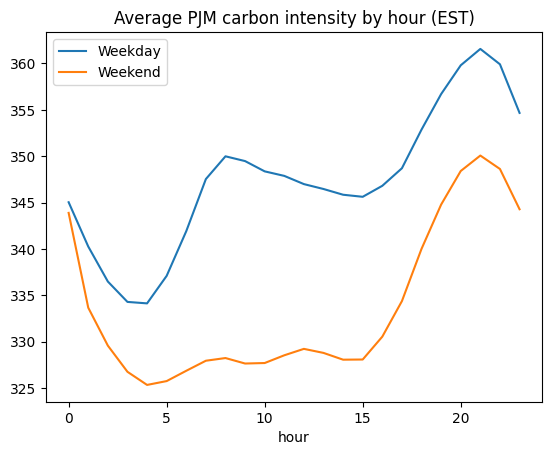

Cleanest hour 4 | Dirtiest hour:  21


In [58]:
df["hour"] = df.index.hour
df["dayofweek"] = df.index.dayofweek
df["isweekend"] = (df["dayofweek"] >= 5).astype(int)

by_hour = df.groupby(["hour", "isweekend"])["carbon intensity"].mean().unstack()
by_hour.columns = ["Weekday", "Weekend"]
by_hour.plot(title = "Average PJM carbon intensity by hour (EST)")
plt.show()
print("Cleanest hour", by_hour["Weekday"].idxmin(), "| Dirtiest hour: ", by_hour["Weekday"].idxmax())

**Observations:** 
- Weekends are consistently cleaner than weekdays. A likely reason for this is because workplaces use more electricity on weekdays, so the grid has to run on fossil fuels to keep up with the midday demand for energy.
- Both peak around 9PM, meaning the dirtiest energy is produced in the evening.
- Carbon intensity for both falls during the night, reaching its cleanest hour around 4:00 AM.
- Weekdays have a second rise around 9:00 AM, which is likely caused by businesses demanding energy.

## 3. Predicting Each Hour's Carbon Intensity
Training a model to predict each hour's carbon intensity from hour of day, day of the week, month, and the value at the same hour yesterday. We will train on data before August 2026 and test on August 2026 and onward, which the model will never see during training.

In [59]:
df["month"] = df.index.month # we also want to take months into account because climate could impact energy consumption
df["carbon intensity yesterday"] = df["carbon intensity"].shift(24, freq="h")

model_df = df.dropna() # drop hours with missing values and the first day, which doesn't have a "yesterday" to go off of
print("Rows for modeling: ", len(model_df))

Rows for modeling:  70898


In [60]:
features = ["hour", "dayofweek", "isweekend", "month", "carbon intensity yesterday"]
target = "carbon intensity"

train = model_df[model_df.index < "2026-08-01"] # model will be trained off of all hours prior to August 1, 2026
test = model_df[model_df.index >= "2026-08-01"] # model will be tested on hours in August 2026 and onwards

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]
print("Train: ", len(train), "hours | Test: ", len(test), "hours")

Train:  68482 hours | Test:  2416 hours


In [61]:
baseline_mae = mean_absolute_error(y_test, test["carbon intensity yesterday"])
print(f"Baseline (same as yesterday): {baseline_mae:.1f} g CO2/kWh")

Baseline (same as yesterday): 15.9 g CO2/kWh


In [62]:
lin = LinearRegression()
lin.fit(X_train, y_train)
lin_mae = mean_absolute_error(y_test, lin.predict(X_test))

rf = RandomForestRegressor(n_estimators = 100, random_state = 42, n_jobs = -1)
rf.fit(X_train, y_train)
rf_mae = mean_absolute_error(y_test, rf.predict(X_test))

results = pd.DataFrame({"Model": ["Baseline (same as yesterday)", "Linear regression", "Random forest"],"MAE (g CO₂/kWh)": [baseline_mae, lin_mae, rf_mae]}).round(1)
results

/Users/dilanmeswani/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dilanmeswani/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dilanmeswani/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


,Model,MAE (g CO₂/kWh)
0,Baseline (same as yesterday),15.9
1,Linear regression,14.5
2,Random forest,15.0


In [64]:
num = 24 * 7 # represents first week
num

168

/Users/dilanmeswani/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dilanmeswani/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dilanmeswani/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


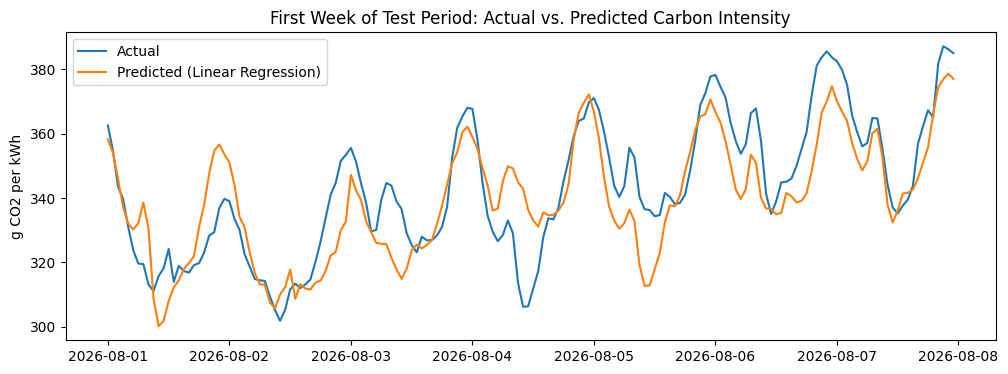

In [68]:
best_predictions = lin.predict(X_test) # Linear regression is the best model
week = test.iloc[:168].copy() # first 7 days of the test period
week["predicted"] = best_predictions[:168]

plt.figure(figsize= (12, 4))
plt.plot(week.index, week["carbon intensity"], label = "Actual")
plt.plot(week.index, week["predicted"], label = "Predicted (Linear Regression)")
plt.title("First Week of Test Period: Actual vs. Predicted Carbon Intensity")
plt.ylabel("g CO2 per kWh")
plt.legend()
plt.show()

**Findings:** 
- Both linear regression (14.5) and random forest (15.0) beat the baseline (15.9).
- Linear regression performed the best, as it has the lowest MAE.
- Looking at the graph, linear regression closely follows the actual patterns, but sometimes overshoots/undershoots by a wide margin